--- STAGE 1 & 2: DATA LOADING & EXPLORATION ---
First 10 records:
   Variance  Skewness  Curtosis  Entropy  Class
0   3.62160    8.6661  -2.80730 -0.44699      0
1   4.54590    8.1674  -2.45860 -1.46210      0
2   3.86600   -2.6383   1.92420  0.10645      0
3   3.45660    9.5228  -4.01120 -3.59440      0
4   0.32924   -4.4552   4.57180 -0.98880      0
5   4.36840    9.6718  -3.96060 -3.16250      0
6   3.59120    3.0129   0.72888  0.56421      0
7   2.09220   -6.8100   8.46360 -0.60216      0
8   3.20320    5.7588  -0.75345 -0.61251      0
9   1.53560    9.1772  -2.27180 -0.73535      0

Shape: (1372, 5)
Missing Values:
 Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64
Duplicate Records: 24

Class Distribution Counts:
Class
0    762
1    610
Name: count, dtype: int64

Class Distribution Percentages:
Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64

--- STAGE 3: GENERATING VISUALISATIONS ---


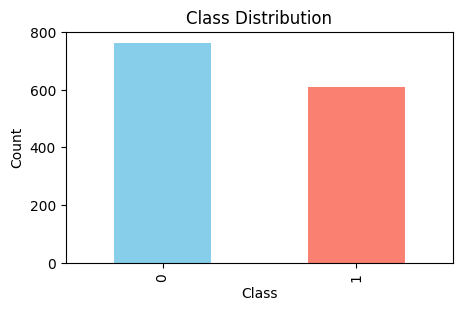

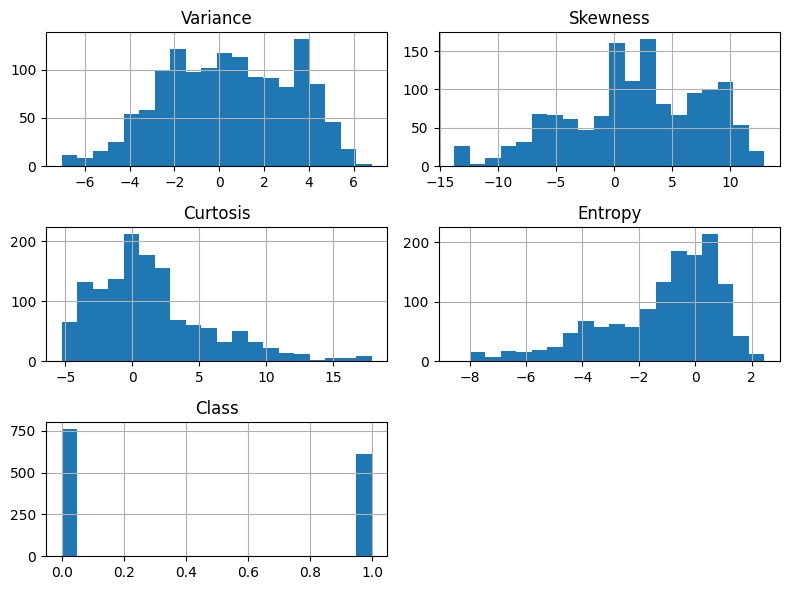

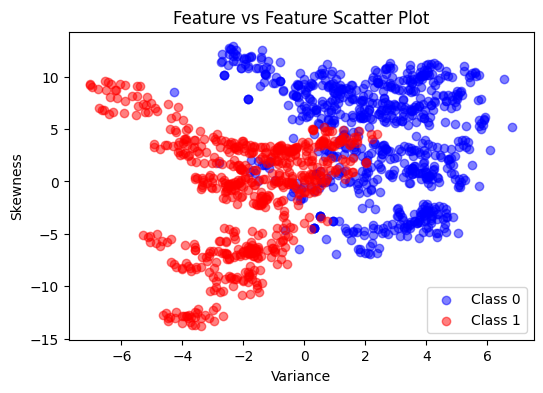


--- STAGE 4 & 5: SPLITTING DATASET ---
Training set shape: (1097, 4)
Testing set shape: (275, 4)

--- STAGE 6 & 7: SCALING & TRAINING MODEL ---
Model training completed successfully.

--- STAGE 8: PREDICTIONS & PROBABILITIES ---
Actual vs Predicted (First 15):
       Actual  Predicted
385        0          0
899        1          1
47         0          0
1018       1          1
786        1          1
1346       1          1
645        0          0
32         0          0
200        0          0
887        1          1
646        0          0
1270       1          1
52         0          0
201        0          0
347        0          0

Probabilities (First 10):
    Prob_Class_0  Prob_Class_1  Actual  Predicted
0      0.999576      0.000424       0          0
1      0.033572      0.966428       1          1
2      0.755631      0.244369       0          0
3      0.035568      0.964432       1          1
4      0.006959      0.993041       1          1
5      0.259981      0.740019  

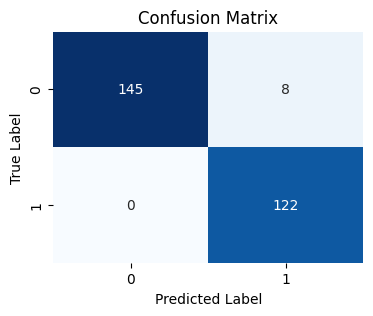


--- STAGE 11: THRESHOLD INVESTIGATION ---
   Threshold  Accuracy  Precision  Recall  F1-Score
0        0.3  0.970909   0.938462     1.0  0.968254
1        0.5  0.970909   0.938462     1.0  0.968254
2        0.7  0.996364   0.991870     1.0  0.995918

Execution complete!


In [ ]:
# ==========================================
# BANKNOTE AUTHENTICATION - LOGISTIC REGRESSION
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# ------------------------------------------
# STAGE 1 & 2: LOAD AND EXPLORE DATASET
# ------------------------------------------
print("--- STAGE 1 & 2: DATA LOADING & EXPLORATION ---")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
column_names = ['Variance', 'Skewness', 'Curtosis', 'Entropy', 'Class']
df = pd.read_csv(url, header=None, names=column_names)

print("First 10 records:")
print(df.head(10))

print("\nShape:", df.shape)
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nClass Distribution Counts:")
print(df['Class'].value_counts())
print("\nClass Distribution Percentages:")
print(df['Class'].value_counts(normalize=True) * 100)

# ------------------------------------------
# STAGE 3: VISUALISE DATASET
# ------------------------------------------
print("\n--- STAGE 3: GENERATING VISUALISATIONS ---")
# Bar chart for class distribution
plt.figure(figsize=(5, 3))
df['Class'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Histograms for features
df.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

# Scatter plot
plt.figure(figsize=(6, 4))
plt.scatter(df[df['Class'] == 0]['Variance'], df[df['Class'] == 0]['Skewness'], color='blue', label='Class 0', alpha=0.5)
plt.scatter(df[df['Class'] == 1]['Variance'], df[df['Class'] == 1]['Skewness'], color='red', label='Class 1', alpha=0.5)
plt.xlabel('Variance')
plt.ylabel('Skewness')
plt.legend()
plt.title('Feature vs Feature Scatter Plot')
plt.show()

# ------------------------------------------
# STAGE 4 & 5: IDENTIFY INPUTS/TARGET & SPLIT
# ------------------------------------------
print("\n--- STAGE 4 & 5: SPLITTING DATASET ---")
X = df[['Variance', 'Skewness', 'Curtosis', 'Entropy']]
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# ------------------------------------------
# STAGE 6 & 7: FEATURE SCALING & TRAINING
# ------------------------------------------
print("\n--- STAGE 6 & 7: SCALING & TRAINING MODEL ---")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
print("Model training completed successfully.")

# ------------------------------------------
# STAGE 8: PREDICTIONS AND PROBABILITIES
# ------------------------------------------
print("\n--- STAGE 8: PREDICTIONS & PROBABILITIES ---")
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)

comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred}).head(15)
print("Actual vs Predicted (First 15):\n", comparison_df)

prob_df = pd.DataFrame(y_prob, columns=['Prob_Class_0', 'Prob_Class_1'])
prob_df['Actual'] = y_test.values
prob_df['Predicted'] = y_pred
print("\nProbabilities (First 10):\n", prob_df.head(10))

# ------------------------------------------
# STAGE 9 & 10: EVALUATION & CONFUSION MATRIX
# ------------------------------------------
print("\n--- STAGE 9 & 10: EVALUATION & CONFUSION MATRIX ---")
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision (Class 1): {prec:.4f}")
print(f"Recall (Class 1): {rec:.4f}")
print(f"F1-score (Class 1): {f1:.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# ------------------------------------------
# STAGE 11: THRESHOLD INVESTIGATION
# ------------------------------------------
print("\n--- STAGE 11: THRESHOLD INVESTIGATION ---")
thresholds = [0.30, 0.50, 0.70]
results = []

for thresh in thresholds:
    custom_preds = (y_prob[:, 1] >= thresh).astype(int)

    acc_t = accuracy_score(y_test, custom_preds)
    prec_t = precision_score(y_test, custom_preds, pos_label=1, zero_division=0)
    rec_t = recall_score(y_test, custom_preds, pos_label=1, zero_division=0)
    f1_t = f1_score(y_test, custom_preds, pos_label=1, zero_division=0)

    results.append({
        'Threshold': thresh,
        'Accuracy': acc_t,
        'Precision': prec_t,
        'Recall': rec_t,
        'F1-Score': f1_t
    })

threshold_df = pd.DataFrame(results)
print(threshold_df)
print("\nExecution complete!")